# comparing bc models with or without actions in the states

In [19]:
import os
import h5py
import pandas as pd
import numpy as np
import json
from scipy.stats import wilcoxon

In [20]:
import sys
sys.path.insert(0, "/home/jake/Documents/AI_Clinician/ai_clinician_pediatric_rl")

from src.data.data_processor_for_shards import ShardProcessor

In [21]:
models_dir = "/home/jake/Documents/AI_Clinician/models/bc_transformer/choc/sepsis/intake-vis/"
with_actions_dir = "with_actions"
with_actions_path = os.path.join(models_dir, with_actions_dir)
without_actions_dir = "without_actions"
without_actions_path = os.path.join(models_dir, without_actions_dir)

if with_actions_dir not in os.listdir(models_dir):
    os.mkdir(with_actions_path)
if without_actions_dir not in os.listdir(models_dir):
    os.mkdir(without_actions_path)

random_search_folder_name = "choc_bc_transformer_action_standard_sepsis"

# create a list of all folders that begin with the random search folder name
random_search_folders = [f for f in os.listdir(models_dir) if f.startswith(random_search_folder_name)]

for folder in random_search_folders:
    # list the folders inside folder
    inner_folders = os.listdir(os.path.join(models_dir, folder))

    # load results.json from inner_folders[0]
    for inner_folder in inner_folders:
        if inner_folder == "config_manager.pkl":
            continue

        with open(os.path.join(models_dir, folder, inner_folder, "results.json"), "r") as f:
            results = json.load(f)
            actions_in_state = results['hyperparameters']['actions_in_state']
            print(f"Folder: {folder}, Actions in state: {actions_in_state}")

            if actions_in_state:
                # move folder to with_actions_dir
                os.rename(os.path.join(models_dir, folder), os.path.join(with_actions_path, folder))
            else:
                # move folder to without_actions_dir
                os.rename(os.path.join(models_dir, folder), os.path.join(without_actions_path, folder))
            break


Folder: choc_bc_transformer_action_standard_sepsis_split_0_20260530_083017_555159_job2891461.pbs-7, Actions in state: True
Folder: choc_bc_transformer_action_standard_sepsis_split_0_20260531_161326_224123_job2898094.pbs-7, Actions in state: True
Folder: choc_bc_transformer_action_standard_sepsis_split_0_20260531_165452_786553_job2898095.pbs-7, Actions in state: True
Folder: choc_bc_transformer_action_standard_sepsis_split_0_20260530_081459_123272_job2891459.pbs-7, Actions in state: True
Folder: choc_bc_transformer_action_standard_sepsis_split_0_20260531_160833_949996_job2898093.pbs-7, Actions in state: True
Folder: choc_bc_transformer_action_standard_sepsis_split_0_20260531_153104_188039_job2898092.pbs-7, Actions in state: True


In [22]:
directories = [with_actions_path, without_actions_path]
for directory in directories:
    inner_folder_list = []
    inner_inner_folder_list = []
    val_mse_list = []
    
    # list the folders inside directory
    inner_folders = os.listdir(directory)

    for inner_folder in inner_folders:
        
        inner_inner_folders = os.listdir(os.path.join(directory, inner_folder))

        for inner_inner_folder in inner_inner_folders:
            if inner_inner_folder == "config_manager.pkl":
                continue

            with open(os.path.join(directory, inner_folder, inner_inner_folder, "results.json"), "r") as f:
                results = json.load(f)

                val_mse = results['val_scores']['val/mse']

                inner_folder_list.append(inner_folder)
                inner_inner_folder_list.append(inner_inner_folder)
                val_mse_list.append(val_mse)

    # find index of the best val_mse
    best_index = np.argmin(val_mse_list)
    best_inner_folder = inner_folder_list[best_index]
    best_inner_inner_folder = inner_inner_folder_list[best_index]
    print(f"Best inner inner folder in {directory}: {best_inner_folder} {best_inner_inner_folder} with val_mse: {val_mse_list[best_index]}")

    # create a final_model dir in directory if it doesn't exist, and move the best_inner_inner_folder to final_model
    final_model_dir = os.path.join(directory, "final_model")
    if not os.path.exists(final_model_dir):
        os.makedirs(final_model_dir)
    os.rename(os.path.join(directory, best_inner_folder, best_inner_inner_folder), os.path.join(final_model_dir, best_inner_inner_folder))


Best inner inner folder in /home/jake/Documents/AI_Clinician/models/bc_transformer/choc/sepsis/intake-vis/with_actions: choc_bc_transformer_action_standard_sepsis_split_0_20260531_153104_188039_job2898092.pbs-7 unknown_cx3-20-3_20260531-160828_79f0d952 with val_mse: [0.026644915974299823]
Best inner inner folder in /home/jake/Documents/AI_Clinician/models/bc_transformer/choc/sepsis/intake-vis/without_actions: final_model unknown_cx3-20-5_20260530-013420_cb7196c0 with val_mse: [0.05129620506029044]


In [23]:
actions = ['intake', 'vis']

models_dir = "/home/jake/Documents/AI_Clinician/models/bc_transformer/choc/sepsis/intake-vis/"
with_actions_dir = os.path.join(models_dir, "with_actions", "final_model")
without_actions_dir = os.path.join(models_dir, "without_actions", "final_model")

# find the folder inside with_actions_dir and without_actions_dir
with_actions_experiment_dir = os.path.join(with_actions_dir, os.listdir(with_actions_dir)[0])
without_actions_experiment_dir = os.path.join(without_actions_dir, os.listdir(without_actions_dir)[0])

predictions_file = "test_set_predictions.h5"

# load the predictions from both models
keys_to_load = ['stay_ids', 'index_ptr', 'predictions', 'targets', 'event']
with_actions_predictions_path = os.path.join(with_actions_experiment_dir, predictions_file)
with_actions_predictions =  ShardProcessor.load_dynamic_deephit_predictions_from_h5(
    with_actions_predictions_path, 
    keys_to_load=keys_to_load, 
    keys_to_exclude=None
)

without_actions_predictions_path = os.path.join(without_actions_experiment_dir, predictions_file)
without_actions_predictions =  ShardProcessor.load_dynamic_deephit_predictions_from_h5(
    without_actions_predictions_path,
    keys_to_load=keys_to_load,
    keys_to_exclude=None
)

In [24]:
# calculate squared error for each prediction, then perform Wilcoxon signed-rank test to compare the two models' predictions
with_actions_squared_error = (with_actions_predictions['predictions'] - with_actions_predictions['targets']) ** 2
without_actions_squared_error = (without_actions_predictions['predictions'] - without_actions_predictions['targets']) ** 2

In [25]:
# compare the two models using the Wilcoxon signed-rank test on each action in actions
for i, action in enumerate(actions):
    with_actions_error_for_action = with_actions_squared_error[:, i]
    without_actions_error_for_action = without_actions_squared_error[:, i]

    # print the mean and median values for each model for this action
    print(f"Action: {action}, With actions - mean squared error: {np.mean(with_actions_error_for_action)}, \
          median squared error: {np.median(with_actions_error_for_action)}")
    print(f"Action: {action}, Without actions - mean squared error: {np.mean(without_actions_error_for_action)}, \
          median squared error: {np.median(without_actions_error_for_action)}")
    
    stat, p_value = wilcoxon(with_actions_error_for_action, without_actions_error_for_action)
    print(f"Action: {action}, Wilcoxon statistic: {stat}, p-value: {p_value}")

    # quantify the effect size using Cohen's d
    mean_diff = np.mean(with_actions_error_for_action - without_actions_error_for_action)
    pooled_std = np.sqrt((np.std(with_actions_error_for_action) ** 2 + np.std(without_actions_error_for_action) ** 2) / 2)
    cohens_d = mean_diff / pooled_std
    print(f"Action: {action}, Cohen's d: {cohens_d}")


Action: intake, With actions - mean squared error: 0.02847503311932087,           median squared error: 0.00729502784088254
Action: intake, Without actions - mean squared error: 0.03406587988138199,           median squared error: 0.009386035613715649
Action: intake, Wilcoxon statistic: 8339423990.0, p-value: 0.0
Action: intake, Cohen's d: -0.10212057163609696
Action: vis, With actions - mean squared error: 0.004064091946929693,           median squared error: 3.059861342080694e-07
Action: vis, Without actions - mean squared error: 0.0067247929982841015,           median squared error: 2.563158341217786e-05
Action: vis, Wilcoxon statistic: 2331650335.5, p-value: 0.0
Action: vis, Cohen's d: -0.137684253330293


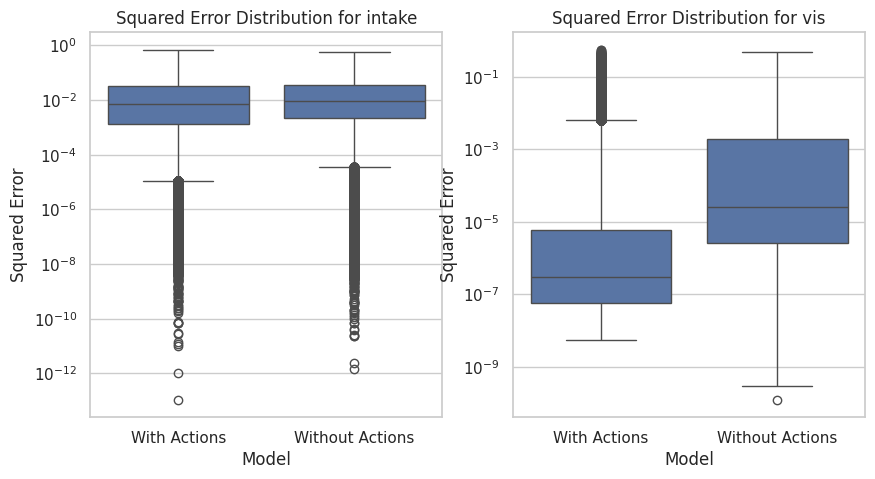

In [26]:
# create plot with 2 subplots, one for each action, showing the distribution of squared errors for each model using boxplots
# on a log scale, since the squared errors can be very large
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")
plt.figure(figsize=(10, 5))
for i, action in enumerate(actions):
    with_actions_error_for_action = with_actions_squared_error[:, i]
    without_actions_error_for_action = without_actions_squared_error[:, i]

    data = {
        'With Actions': with_actions_error_for_action,
        'Without Actions': without_actions_error_for_action
    }
    df = pd.DataFrame(data)

    df_melted = df.melt(var_name='Model', value_name='Squared Error')

    plt.subplot(1, 2, i+1)
    # plot on log scale
    plt.yscale('log')
    
    sns.boxplot(x='Model', y='Squared Error', data=df_melted)
    plt.title(f'Squared Error Distribution for {action}')


